In [13]:
# NORDHAUSEN 0.99 MWp — DIGITAL TWIN (FINAL)


#   Physics: De Soto SDM · bifaciality · horizon shading
#           inverter curve · Pmax TC · mismatch · 3 scenarios
#   ML:      LSTM residual learner · XGBoost ECM (q05/q50/q95)
#   Output:  24h operational forecast · combined uncertainty intervals


In [14]:
from google.colab import drive
drive.mount("/content/drive")

# Install packages not available by default on Colab
import subprocess
subprocess.run(["pip", "install", "pvlib", "pywavelets", "plotly",
                "--quiet"], check=True)

# Verify GPU
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print(f"✅ TensorFlow {tf.__version__}")
print(f"   GPU available: {len(gpus) > 0}  "
      f"({gpus[0].name if gpus else 'CPU only — still works'})")

# ── Set your Google Drive paths here ────────────────────────────────────
DRIVE_BASE = "/content/drive/MyDrive/Digital Twin site validation"

PATH_RAW_WEATHER = (f"{DRIVE_BASE}/"
                    f"14-24 Open meteo weather data.csv")
SNOW_FILE        = (f"{DRIVE_BASE}/"
                    f"nordhausen_snow_2014_2024.csv")
PLANT_FILE       = f"{DRIVE_BASE}/nordhausen_raw.csv"
MARCH_FILE       = f"{DRIVE_BASE}/nordhausen_march2026_live.csv"
MODEL_DIR        = f"{DRIVE_BASE}/model_outputs"


import os
os.makedirs(MODEL_DIR, exist_ok=True)
print(f"✅ Model directory: {MODEL_DIR}")



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ TensorFlow 2.20.0
   GPU available: True  (/physical_device:GPU:0)
✅ Model directory: /content/drive/MyDrive/Digital Twin site validation/model_outputs


In [15]:
from google.colab import drive
drive.mount("/content/drive")

# Install packages not available by default on Colab
import subprocess
subprocess.run(["pip", "install", "pvlib", "pywavelets", "plotly",
                "--quiet"], check=True)

# Verify GPU
import tensorflow as tf
gpus = tf.config.list_physical_devices("GPU")
print(f"✅ TensorFlow {tf.__version__}")
print(f"   GPU available: {len(gpus) > 0}  "
      f"({gpus[0].name if gpus else 'CPU only — still works'})")

# ── Set your Google Drive paths here ────────────────────────────────────
DRIVE_BASE = "/content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Digital Twin/Digital Twin site validation"

PATH_RAW_WEATHER = (f"{DRIVE_BASE}/"
                    f"14-24 Open meteo weather data.csv")
SNOW_FILE        = (f"{DRIVE_BASE}/"
                    f"nordhausen_snow_2014_2024.csv")
PLANT_FILE       = f"{DRIVE_BASE}/nordhausen_raw.csv"
MARCH_FILE       = f"{DRIVE_BASE}/nordhausen_march2026_live.csv"
MODEL_DIR        = f"{DRIVE_BASE}/model_outputs"


import os
os.makedirs(MODEL_DIR, exist_ok=True)
print(f"✅ Model directory: {MODEL_DIR}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ TensorFlow 2.20.0
   GPU available: True  (/physical_device:GPU:0)
✅ Model directory: /content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Digital Twin/Digital Twin site validation/model_outputs


In [16]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 2 — IMPORTS + CONSTANTS
# ════════════════════════════════════════════════════════════════════════════

import os, warnings, time, requests, json
from datetime import date, timedelta

import numpy as np
import pandas as pd
import pywt
import pvlib
import joblib
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.optimizers import Adam

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

# ── Site ──────────────────────────────────────────────────────────────────
LATITUDE   = 51.502
LONGITUDE  = 10.796
ALTITUDE   = 180
TIMEZONE   = "Europe/Berlin"

# ── Plant ─────────────────────────────────────────────────────────────────
ARRAYS = [
    {"name": "East", "azimuth": 111.7, "tilt": 8.0, "capacity_kwp": 495.0},
    {"name": "West", "azimuth": 291.7, "tilt": 8.0, "capacity_kwp": 495.0},
]
TOTAL_KWP      = 990.0
INVERTER_KW_AC = 900.0
INSTALL_YEAR   = 2015

# ── De Soto parameters from measured I-V data ────────────────────────────
DESOTO = {
    "I_L_ref": 9.993477, "I_o_ref": 3.613426e-11,
    "R_s": 0.257688, "R_sh_ref": 190.811829, "a_ref": 1.530902,
    "alpha_sc": 0.004192, "EgRef": 1.121, "dEgdT": -0.0002677,
    "irrad_ref": 1000.0, "temp_ref": 25.0,
}

# ── Physics uncertainty scenarios ────────────────────────────────────────
MODULE_SCENARIOS = {
    "pmp_low": 300.0, "pmp_central": 310.0, "pmp_high": 370.0,
    "bifaciality": 0.275,
    "albedo_low": 0.10, "albedo_central": 0.20, "albedo_high": 0.35,
    "degrad_low": -0.002, "degrad_central": -0.003, "degrad_high": -0.005,
    "pmax_tc": -0.0035,
    "horizon_elev_low": 3.0, "horizon_elev_central": 7.0,
    "horizon_elev_high": 12.0,
    "mismatch_low": 0.010, "mismatch_central": 0.020, "mismatch_high": 0.030,
}
MODULE_COUNT = {
    "low"    : int(TOTAL_KWP * 1000 / MODULE_SCENARIOS["pmp_high"]),
    "central": int(TOTAL_KWP * 1000 / MODULE_SCENARIOS["pmp_central"]),
    "high"   : int(TOTAL_KWP * 1000 / MODULE_SCENARIOS["pmp_low"]),
}
TOTAL_SYSTEM_LOSS = 0.93
TEMP_MODEL = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS[
    "sapm"]["open_rack_glass_glass"]

# ── Model constants ───────────────────────────────────────────────────────
WAVELET        = "db4"
N_TIMESTEPS    = 24
LSTM_UNITS     = 128
ECM_LOOKBACK   = 6
TRAINING_START = 2014
TRAINING_END   = 2022

FEATURE_COLS = [
    "ghi", "dni", "dhi", "poa_east", "poa_west",
    "sdm_cf", "sdm_cf_low", "sdm_cf_high",
    "temp_air", "wind_speed_kmh",
    "solar_zenith", "solar_azimuth",
    "hour_sin", "hour_cos", "day_of_year_sin", "day_of_year_cos",
    "clearness_index", "cloud_cover", "is_daytime",
    "rear_irradiance_cf", "shading_factor",
    "snow_depth_cm", "snowfall_cm", "precipitation_mm",
    "soiling_loss", "snow_loss_factor",
    "ghi_wavelet_cA", "ghi_wavelet_cD",
]

# ── File paths ────────────────────────────────────────────────────────────
PATH_X_TRAIN    = f"{MODEL_DIR}/X_train_final.csv"
PATH_Y_TRAIN    = f"{MODEL_DIR}/y_train_final.csv"
MODEL_FILE      = f"{MODEL_DIR}/dt_final_lstm.keras"
FEAT_SCALER     = f"{MODEL_DIR}/dt_final_feat_scaler.joblib"
TGT_SCALER      = f"{MODEL_DIR}/dt_final_tgt_scaler.joblib"
ECM_Q50_FILE    = f"{MODEL_DIR}/dt_final_ecm_q50.joblib"
ECM_Q05_FILE    = f"{MODEL_DIR}/dt_final_ecm_q05.joblib"
ECM_Q95_FILE    = f"{MODEL_DIR}/dt_final_ecm_q95.joblib"
CAL_FILE        = f"{MODEL_DIR}/dt_final_calibration.json"

print("✅ Configuration loaded.")
print(f"   Capacity : {TOTAL_KWP:.0f} kWp  |  Features: {len(FEATURE_COLS)}")
print(f"   Modules  : {MODULE_COUNT['central']} (central scenario)")
print(f"   Scenarios: low={MODULE_COUNT['low']} · "
      f"central={MODULE_COUNT['central']} · high={MODULE_COUNT['high']}")


✅ Configuration loaded.
   Capacity : 990 kWp  |  Features: 28
   Modules  : 3193 (central scenario)
   Scenarios: low=2675 · central=3193 · high=3300


In [17]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 3 — HELPER FUNCTIONS
# ════════════════════════════════════════════════════════════════════════════

def fetch_weather(start_date, end_date, use_archive=True):
    """Fetch hourly weather from Open-Meteo. Handles DST duplicates."""
    url = ("https://archive-api.open-meteo.com/v1/archive"
           if use_archive else
           "https://api.open-meteo.com/v1/forecast")
    params = dict(
        latitude=LATITUDE, longitude=LONGITUDE,
        start_date=start_date, end_date=end_date,
        hourly=("temperature_2m,shortwave_radiation,"
                "direct_normal_irradiance,diffuse_radiation,"
                "windspeed_10m,snowfall,snow_depth,precipitation"),
        windspeed_unit="kmh", timezone=TIMEZONE,
    )
    r = requests.get(url, params=params, timeout=30)
    r.raise_for_status()
    df = pd.DataFrame(r.json()["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    df = df.set_index("time")
    df = df[~df.index.duplicated(keep="first")]
    df.index = df.index.tz_localize(
        TIMEZONE, ambiguous="NaT", nonexistent="NaT")
    df = df[~df.index.duplicated(keep="first")]
    return df.rename(columns={
        "temperature_2m": "temp_air", "windspeed_10m": "wind_speed_kmh",
        "shortwave_radiation": "ghi", "direct_normal_irradiance": "dni",
        "diffuse_radiation": "dhi", "snowfall": "snowfall_cm",
        "snow_depth": "snow_depth_cm", "precipitation": "precipitation_mm",
    }).fillna(0)


def inverter_efficiency(dc_kw):
    """Load-dependent inverter efficiency curve."""
    load = np.clip(dc_kw.values / INVERTER_KW_AC, 0, 1)
    eff  = np.where(load < 0.02, 0.0,
           np.where(load < 0.05, 0.88 + load * 1.4,
           np.where(load < 0.10, 0.930 + load * 0.80,
           np.where(load < 0.20, 0.958 + load * 0.22,
           np.where(load < 0.50, 0.970 + load * 0.025, 0.975)))))
    return pd.Series(np.clip(eff, 0, 0.975), index=dc_kw.index)


def compute_snow_loss(snow_depth_cm, snowfall_cm, temp_air, tilt=8.0):
    slide = np.sin(np.radians(tilt)) / np.sin(np.radians(35))
    depth_factor = np.clip(snow_depth_cm / 20.0, 0, 1) * (1 - slide)
    temp_factor  = np.where(temp_air > 3.0, 0.0,
                   np.where(temp_air > 0.0,
                            0.5 * (3.0 - temp_air) / 3.0, 1.0))
    active = (snow_depth_cm > 1.0).astype(float)
    return pd.Series(np.clip(depth_factor * temp_factor * active * 0.95, 0, 1),
                     index=snow_depth_cm.index, name="snow_loss_factor")


def compute_soiling_loss(precipitation_mm, tilt=8.0):
    tilt_factor = 1.0 + (30.0 - tilt) / 30.0 * 0.5
    RATE = 0.0003 * tilt_factor
    soiling = np.zeros(len(precipitation_mm))
    cur = 0.0
    for i, rain in enumerate(precipitation_mm.values):
        cur = cur * 0.1 if rain >= 1.0 else min(cur + RATE, 0.05)
        soiling[i] = cur
    return pd.Series(soiling, index=precipitation_mm.index, name="soiling_loss")


def compute_horizon_shading(sp, array_azimuth, horizon_elev=7.0):
    """Horizon shading factor [0,1] per array azimuth."""
    sun_elev  = 90.0 - sp["apparent_zenith"].values
    sun_az    = sp["azimuth"].values
    az_diff   = np.abs(((sun_az - array_azimuth + 180) % 360) - 180)
    in_sector = az_diff < 60
    ramp_top  = horizon_elev + 5.0
    shade = np.where(
        ~in_sector, 1.0,
        np.where(sun_elev <= 0, 0.0,
        np.where(sun_elev < horizon_elev, 0.0,
        np.where(sun_elev < ramp_top,
                 (sun_elev - horizon_elev) / 5.0, 1.0))))
    return pd.Series(shade, index=sp.index)


def run_sdm_scenario(df, sp, scenario="central"):
    """Run SDM for one parameter scenario → normalised capacity factor [0,1]."""
    ms = MODULE_SCENARIOS
    n_mod = MODULE_COUNT[scenario]
    albedo   = {"low": ms["albedo_low"],
                "central": ms["albedo_central"],
                "high": ms["albedo_high"]}[scenario]
    degrad   = {"low": ms["degrad_high"],
                "central": ms["degrad_central"],
                "high": ms["degrad_low"]}[scenario]
    horizon  = {"low": ms["horizon_elev_high"],
                "central": ms["horizon_elev_central"],
                "high": ms["horizon_elev_low"]}[scenario]
    mismatch = {"low": ms["mismatch_high"],
                "central": ms["mismatch_central"],
                "high": ms["mismatch_low"]}[scenario]

    tilt_rad    = np.radians(ARRAYS[0]["tilt"])
    view_factor = (1 - np.cos(tilt_rad)) / 2
    rear_irr    = (df["ghi"] * albedo * view_factor *
                   ms["bifaciality"]).clip(lower=0)
    rear_irr[sp["apparent_zenith"] >= 90.0] = 0.0

    snow_l   = df.get("snow_loss_factor", pd.Series(0.0, index=df.index))
    soil_l   = df.get("soiling_loss",     pd.Series(0.0, index=df.index))
    avail    = 1.0 - np.clip(snow_l + soil_l, 0, 0.99)
    years_e  = df.index.year - INSTALL_YEAR
    deg      = (1 + degrad) ** years_e

    total_dc = pd.Series(0.0, index=df.index)
    for arr in ARRAYS:
        shading = compute_horizon_shading(sp, arr["azimuth"], horizon)
        poa = pvlib.irradiance.get_total_irradiance(
            arr["tilt"], arr["azimuth"],
            sp["apparent_zenith"], sp["azimuth"],
            dni=df["dni"], ghi=df["ghi"], dhi=df["dhi"])
        poa_g   = poa["poa_global"].fillna(0).clip(lower=0) * shading.values
        wind    = df["wind_speed_kmh"] / 3.6
        tcell   = pvlib.temperature.sapm_cell(
            poa_g, df["temp_air"], wind, **TEMP_MODEL)
        eff_irr = (poa_g + rear_irr * 0.5) * avail * deg
        params  = pvlib.pvsystem.calcparams_desoto(
            effective_irradiance=eff_irr, temp_cell=tcell,
            alpha_sc=DESOTO["alpha_sc"], a_ref=DESOTO["a_ref"],
            I_L_ref=DESOTO["I_L_ref"], I_o_ref=DESOTO["I_o_ref"],
            R_sh_ref=DESOTO["R_sh_ref"], R_s=DESOTO["R_s"],
            EgRef=DESOTO["EgRef"], dEgdT=DESOTO["dEgdT"],
            irrad_ref=DESOTO["irrad_ref"], temp_ref=DESOTO["temp_ref"],
        )
        iv = pvlib.pvsystem.singlediode(*params)
        dc = iv["p_mp"] * (n_mod // 2) / 1000.0
        temp_correction = (1.0 + ms["pmax_tc"] * (tcell - 25.0)).clip(lower=0.5)
        irr_factor = np.clip(eff_irr / 1000.0, 0, 1)
        dc = dc * temp_correction * (1.0 - mismatch * (2.0 - irr_factor))
        total_dc += dc.fillna(0).clip(lower=0)

    eff_inv = inverter_efficiency(total_dc)
    ac_kw   = (total_dc * eff_inv * TOTAL_SYSTEM_LOSS
               ).clip(upper=INVERTER_KW_AC)
    ac_kw[sp["apparent_zenith"] >= 90.0] = 0.0
    cf = (ac_kw / (TOTAL_KWP * 0.975)).clip(0, 1)
    return cf.rename(f"sdm_cf_{scenario}")


def engineer_features(df, location):
    """Full feature engineering — consistent between training and inference."""
    df = df.copy()
    sp = location.get_solarposition(df.index)
    df["solar_zenith"]  = sp["apparent_zenith"]
    df["solar_azimuth"] = sp["azimuth"]
    df["is_daytime"]    = (sp["apparent_zenith"] < 90.0).astype(float)

    for arr in ARRAYS:
        poa = pvlib.irradiance.get_total_irradiance(
            arr["tilt"], arr["azimuth"],
            sp["apparent_zenith"], sp["azimuth"],
            dni=df["dni"], ghi=df["ghi"], dhi=df["dhi"])
        key = "poa_east" if arr["name"] == "East" else "poa_west"
        df[key] = poa["poa_global"].fillna(0).clip(lower=0)

    df["hour_sin"]        = np.sin(2*np.pi*df.index.hour/24)
    df["hour_cos"]        = np.cos(2*np.pi*df.index.hour/24)
    df["day_of_year_sin"] = np.sin(2*np.pi*df.index.dayofyear/365)
    df["day_of_year_cos"] = np.cos(2*np.pi*df.index.dayofyear/365)

    cs   = location.get_clearsky(df.index)
    cghi = cs["ghi"].clip(lower=1.0)
    df["clearness_index"] = (df["ghi"] / cghi).fillna(0).clip(0, 1)
    df["cloud_cover"]     = 1 - df["clearness_index"]

    snow   = df.get("snow_depth_cm",    pd.Series(0.0, index=df.index))
    snowf  = df.get("snowfall_cm",      pd.Series(0.0, index=df.index))
    precip = df.get("precipitation_mm", pd.Series(0.0, index=df.index))
    df["snow_loss_factor"] = compute_snow_loss(snow, snowf, df["temp_air"])
    df["soiling_loss"]     = compute_soiling_loss(precip)
    for c in ["snow_depth_cm", "snowfall_cm", "precipitation_mm"]:
        if c not in df.columns:
            df[c] = 0.0

    # Three SDM scenarios
    df["sdm_cf"]      = run_sdm_scenario(df, sp, "central")
    df["sdm_cf_low"]  = run_sdm_scenario(df, sp, "low")
    df["sdm_cf_high"] = run_sdm_scenario(df, sp, "high")

    # Shading factor (average E+W)
    shade_e = compute_horizon_shading(
        sp, ARRAYS[0]["azimuth"], MODULE_SCENARIOS["horizon_elev_central"])
    shade_w = compute_horizon_shading(
        sp, ARRAYS[1]["azimuth"], MODULE_SCENARIOS["horizon_elev_central"])
    df["shading_factor"] = ((shade_e + shade_w) / 2).values

    # Bifacial rear irradiance
    tilt_rad    = np.radians(ARRAYS[0]["tilt"])
    view_factor = (1 - np.cos(tilt_rad)) / 2
    rear = (df["ghi"] * MODULE_SCENARIOS["albedo_central"] *
            view_factor * MODULE_SCENARIOS["bifaciality"]).clip(lower=0)
    rear[sp["apparent_zenith"] >= 90.0] = 0.0
    df["rear_irradiance_cf"] = (rear / (TOTAL_KWP * 0.975 + 1e-6)).clip(0, 0.08)

    return df


def add_wavelet(df):
    df = df.copy()
    cA, cD = pywt.dwt(df["ghi"].values, WAVELET)
    df["ghi_wavelet_cA"] = np.repeat(cA, 2)[:len(df)]
    df["ghi_wavelet_cD"] = np.repeat(cD, 2)[:len(df)]
    return df[[c for c in FEATURE_COLS if c in df.columns]]


def build_sequences(X_sc, y_sc, n_steps):
    Xs, ys = [], []
    for i in range(n_steps, len(X_sc)):
        Xs.append(X_sc[i-n_steps:i])
        ys.append(y_sc[i])
    return np.array(Xs), np.array(ys)


def metrics_report(actual, predicted, label, peak_kw=None):
    day  = actual > 5.0
    a, p = actual[day].values, predicted[day].values
    r2   = r2_score(a, p)
    rmse = np.sqrt(mean_squared_error(a, p))
    mae  = mean_absolute_error(a, p)
    pk   = peak_kw if peak_kw else actual.max()
    nrm  = rmse / pk * 100
    sig  = a > pk * 0.05
    mape = np.mean(np.abs((a[sig]-p[sig])/a[sig]))*100 if sig.sum() > 0 else 0
    print(f"  {label}")
    print(f"    R²    = {r2:.4f}")
    print(f"    RMSE  = {rmse:.1f} kW")
    print(f"    nRMSE = {nrm:.1f}%")
    print(f"    MAE   = {mae:.1f} kW")
    print(f"    MAPE  = {mape:.1f}%")
    return {"label": label, "r2": r2, "rmse": rmse,
            "nrmse": nrm, "mae": mae, "mape": mape}


print("✅ All helper functions defined.")


✅ All helper functions defined.


In [18]:
# CELL 4 — STEP 1: GENERATE TRAINING DATA

print(f"\n=== Step 1: Training Data ({TRAINING_START}–{TRAINING_END}) ===")

df_raw = pd.read_csv(PATH_RAW_WEATHER, encoding="latin1", header=3)
col_map = {
    "time": "timestamp",
    "temperature_2m (°C)": "temp_air",
    "wind_speed_10m (km/h)": "wind_speed_kmh",
    "shortwave_radiation (W/m²)": "ghi",
    "direct_normal_irradiance (W/m²)": "dni",
    "diffuse_radiation (W/m²)": "dhi",
}
df_wx = df_raw.rename(columns=col_map)
df_wx["timestamp"] = pd.to_datetime(df_wx["timestamp"])
df_wx = df_wx[df_wx["timestamp"].dt.year.between(TRAINING_START, TRAINING_END)]
df_wx = (df_wx.set_index("timestamp")
         .tz_localize(TIMEZONE, ambiguous="NaT", nonexistent="NaT"))
df_wx = df_wx[~df_wx.index.duplicated(keep="first")]
full_idx = pd.date_range(f"{TRAINING_START}-01-01",
                          f"{TRAINING_END}-12-31 23:00",
                          freq="h", tz=TIMEZONE)
df_wx = df_wx.reindex(full_idx).interpolate(method="time").bfill()

# ── Load snow from local file ─────────────────────────────────────────────
print("  Loading snow data from local file...")
try:
    with open(SNOW_FILE, "r") as f:
        raw = f.readlines()
    skip = next((i for i, l in enumerate(raw[:10])
                 if l.strip().lower().startswith("time")), 0)
    df_snow = pd.read_csv(SNOW_FILE, skiprows=skip, parse_dates=["time"])
    df_snow = df_snow.set_index("time")
    df_snow = df_snow[~df_snow.index.duplicated(keep="first")]
    if df_snow.index.tz is None:
        df_snow.index = df_snow.index.tz_localize(
            TIMEZONE, ambiguous="NaT", nonexistent="NaT")
    df_snow = df_snow[~df_snow.index.duplicated(keep="first")]
    df_snow = df_snow.rename(columns={
        "snowfall (cm)"      : "snowfall_cm",
        "snow_depth (m)"     : "snow_depth_cm",
        "precipitation (mm)" : "precipitation_mm",
        "snowfall"           : "snowfall_cm",
        "snow_depth"         : "snow_depth_cm",
        "precipitation"      : "precipitation_mm",
    })
    for col in ["snowfall_cm", "snow_depth_cm", "precipitation_mm"]:
        if col not in df_snow.columns:
            df_snow[col] = 0.0
    for col in ["snowfall_cm", "snow_depth_cm", "precipitation_mm"]:
        df_wx[col] = df_snow[col].reindex(df_wx.index).fillna(0.0)
    print(f"    ✅ Snow loaded  max snow_depth={df_snow['snow_depth_cm'].max():.1f}")
except Exception as e:
    print(f"    ⚠️  Snow load failed ({e}) — using zeros")
    for col in ["snowfall_cm", "snow_depth_cm", "precipitation_mm"]:
        df_wx[col] = 0.0

location = pvlib.location.Location(LATITUDE, LONGITUDE, tz=TIMEZONE)
print("  Engineering features (3 SDM scenarios — ~5 min)...")
df_feat  = engineer_features(df_wx, location)

print("  Adding wavelet decomposition features...")
cA, cD = pywt.dwt(df_feat["ghi"].values, WAVELET)
df_feat["ghi_wavelet_cA"] = np.repeat(cA, 2)[:len(df_feat)]
df_feat["ghi_wavelet_cD"] = np.repeat(cD, 2)[:len(df_feat)]
print(f"    ✅ Wavelet features added (cA range: "
      f"{df_feat['ghi_wavelet_cA'].min():.2f}–{df_feat['ghi_wavelet_cA'].max():.2f})")
# ════════════════════════════════════════════════════════════════════════

y_sdm_kw = df_feat["sdm_cf"] * TOTAL_KWP * 0.975

feat_avail = [c for c in FEATURE_COLS if c in df_feat.columns]
df_feat[feat_avail].to_csv(PATH_X_TRAIN)
y_sdm_kw.to_csv(PATH_Y_TRAIN, header=True)
print(f"✅ Saved  X:{df_feat[feat_avail].shape}  "
      f"sdm_cf range: {df_feat['sdm_cf'].min():.3f}–{df_feat['sdm_cf'].max():.3f}")


=== Step 1: Training Data (2014–2022) ===
  Loading snow data from local file...
    ✅ Snow loaded  max snow_depth=0.3
  Engineering features (3 SDM scenarios — ~5 min)...
  Adding wavelet decomposition features...
    ✅ Wavelet features added (cA range: -46.04–1291.51)
✅ Saved  X:(78888, 28)  sdm_cf range: 0.000–0.686


In [19]:
# CELL 5 — STEP 2: SPLIT + SCALE

print("\n=== Step 2: Split and Scale ===")

X_full = pd.read_csv(PATH_X_TRAIN, index_col=0, parse_dates=True)
y_full = pd.read_csv(PATH_Y_TRAIN, index_col=0, parse_dates=True)
X_full.index = pd.to_datetime(X_full.index, utc=True).tz_convert(TIMEZONE)
y_full.index = pd.to_datetime(y_full.index, utc=True).tz_convert(TIMEZONE)

years   = X_full.index.year
X_train = X_full.loc[years <= 2020]    # ← REMOVED add_wavelet wrapper
X_val   = X_full.loc[years == 2021]    # ← REMOVED
X_test  = X_full.loc[years == 2022]    # ← REMOVED
y_train = y_full.loc[years <= 2020]
y_val   = y_full.loc[years == 2021]
y_test  = y_full.loc[years == 2022]

n_feat  = X_train.shape[1]
feat_sc = MinMaxScaler()
tgt_sc  = MinMaxScaler()
X_tr_sc = feat_sc.fit_transform(X_train)
y_tr_sc = tgt_sc.fit_transform(y_train)
X_vl_sc = feat_sc.transform(X_val)
y_vl_sc = tgt_sc.transform(y_val)
X_te_sc = feat_sc.transform(X_test)
y_te_sc = tgt_sc.transform(y_test)

X_tr_seq, y_tr_seq = build_sequences(X_tr_sc, y_tr_sc, N_TIMESTEPS)
X_vl_seq, y_vl_seq = build_sequences(X_vl_sc, y_vl_sc, N_TIMESTEPS)
X_te_seq, y_te_seq = build_sequences(X_te_sc, y_te_sc, N_TIMESTEPS)

joblib.dump(feat_sc, FEAT_SCALER)
joblib.dump(tgt_sc,  TGT_SCALER)
print(f"  Train: {X_tr_seq.shape}  Val: {X_vl_seq.shape}  "
      f"Test: {X_te_seq.shape}")
print("✅ Scalers saved.")


=== Step 2: Split and Scale ===
  Train: (61344, 24, 28)  Val: (8736, 24, 28)  Test: (8736, 24, 28)
✅ Scalers saved.


In [20]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 6 — STEP 3: TRAIN LSTM
# ════════════════════════════════════════════════════════════════════════════

print("\n=== Step 3: Train LSTM ===")

# Enable mixed precision for faster GPU training


inp = Input(shape=(N_TIMESTEPS, n_feat), name="input")
x   = LSTM(LSTM_UNITS, activation="tanh",
           return_sequences=True, name="lstm_1")(inp)
x   = Dropout(0.2)(x)
x   = LSTM(LSTM_UNITS//2, activation="tanh",
           return_sequences=True, name="lstm_2")(x)
x   = Dropout(0.2)(x)
x   = LSTM(LSTM_UNITS//4, activation="tanh", name="lstm_3")(x)
x   = Dropout(0.1)(x)
x   = Dense(64, activation="relu")(x)
out = Dense(1, activation="relu", name="output")(x)

model = Model(inputs=inp, outputs=out)
model.compile(optimizer=Adam(learning_rate=1e-3), loss="huber")
model.summary()

cbs = [
    ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                      patience=15, min_lr=1e-7, verbose=1),
    EarlyStopping(monitor="val_loss", patience=20,
                  min_delta=1e-6, restore_best_weights=True, verbose=1),
]

t0 = time.time()
model.fit(X_tr_seq, y_tr_seq,
          validation_data=(X_vl_seq, y_vl_seq),
          epochs=150, batch_size=64, callbacks=cbs, verbose=1)
print(f"  Training: {(time.time()-t0)/60:.1f} min")
model.save(MODEL_FILE)
print(f"✅ Model saved → {MODEL_FILE}")

# Evaluate on synthetic 2022 test
y_pred_sc = model.predict(X_te_seq, verbose=0)
y_pred_kw = tgt_sc.inverse_transform(
    y_pred_sc.astype("float32")).flatten()
y_pred_kw = np.clip(y_pred_kw, 0, None)
y_true_kw = y_test.iloc[N_TIMESTEPS:].values.flatten()
sp_te     = location.get_solarposition(y_test.iloc[N_TIMESTEPS:].index)
y_pred_kw[sp_te["apparent_zenith"].values >= 90.0] = 0.0
day_m     = y_true_kw > 1.0
print(f"\n  Synthetic test 2022:")
print(f"    R² all={r2_score(y_true_kw, y_pred_kw):.4f}  "
      f"R² day={r2_score(y_true_kw[day_m], y_pred_kw[day_m]):.4f}")
print(f"    RMSE={np.sqrt(mean_squared_error(y_true_kw,y_pred_kw)):.1f}kW  "
      f"Night={(y_pred_kw[y_true_kw==0]<5).mean()*100:.1f}%")



=== Step 3: Train LSTM ===


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 24, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 24, 128)        │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 24, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 144,385 (564.00 KB)

 Trainable params: 144,385 (564.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 27s 20ms/step - loss: 0.0023 - val_loss: 0.0012 - learning_rate: 0.0010
Epoch 2/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - loss: 0.0012 - val_loss: 0.0012 - learning_rate: 0.0010
Epoch 3/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - loss: 0.0011 - val_loss: 0.0013 - learning_rate: 0.0010
Epoch 4/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - loss: 0.0010 - val_loss: 0.0011 - learning_rate: 0.0010
Epoch 5/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 9.6018e-04 - val_loss: 0.0011 - learning_rate: 0.0010
Epoch 6/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - loss: 9.3447e-04 - val_loss: 0.0011 - learning_rate: 0.0010
Epoch 7/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 9.0778e-04 - val_loss: 0.0011 - learning_rate: 0.0010
Epoch 8/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - loss: 8.7023e-04 - val_loss: 0.0010 - learning_rate: 0.0010
Epoch 9/150
959/959 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - loss: 8.3924e-04 - val_

In [21]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 7 — STEP 4: REAL PLANT VALIDATION + MONTHLY CALIBRATION
# ════════════════════════════════════════════════════════════════════════════

print("\n=== Step 4: Real Plant Validation + Calibration ===")

df_plant = pd.read_csv(PLANT_FILE)
df_plant["timestamp"] = pd.to_datetime(df_plant["timestamp"])
df_plant = df_plant.set_index("timestamp")
df_plant.index = df_plant.index.tz_localize(
    TIMEZONE, ambiguous="NaT", nonexistent="NaT")
df_plant["power_kw"] = df_plant["pv_mwh"].fillna(0) * 1000.0
PEAK_KW = df_plant["power_kw"].max()
print(f"  Plant: {len(df_plant):,} hours  peak={PEAK_KW:.1f} kW")

print("  Fetching 2025 weather from API...")
all_wx = []
s = pd.Timestamp(df_plant.index.min().strftime("%Y-%m-%d"))
e = pd.Timestamp(df_plant.index.max().strftime("%Y-%m-%d"))
while s <= e:
    ce = min(s + pd.DateOffset(months=3), e)
    chunk = fetch_weather(s.strftime("%Y-%m-%d"), ce.strftime("%Y-%m-%d"))
    all_wx.append(chunk)
    print(f"    {s.date()} → {ce.date()}")
    s = ce + pd.DateOffset(days=1)
df_wx2 = pd.concat(all_wx)
df_wx2 = df_wx2[~df_wx2.index.duplicated(keep="first")]

common  = df_plant.index.intersection(df_wx2.index)
common  = common[~common.duplicated()].sort_values()
real_kw = df_plant.loc[common, "power_kw"]

print("  Engineering 2025 features (3 scenarios)...")
df_f2   = engineer_features(df_wx2.loc[common], location)
PATH_X_REAL = f"{MODEL_DIR}/X_real_2025.csv"
PATH_Y_REAL = f"{MODEL_DIR}/y_real_2025.csv"
df_f2[[c for c in FEATURE_COLS if c in df_f2.columns]].to_csv(PATH_X_REAL)
real_kw.to_csv(PATH_Y_REAL, header=["target_power_kw"])
print(f"  ✓ Real-2025 features saved: {PATH_X_REAL}")
print(f"  ✓ Real-2025 target saved:   {PATH_Y_REAL}")

def lstm_predict_kw(df_features, _model, _fsc, _tsc):
    df_w  = add_wavelet(df_features)
    cols  = [c for c in FEATURE_COLS if c in df_w.columns]
    X_sc  = _fsc.transform(df_w[cols])
    X_seq = np.array([X_sc[i-N_TIMESTEPS:i]
                      for i in range(N_TIMESTEPS, len(X_sc))])
    if len(X_seq) == 0:
        return pd.Series(dtype=float)
    y_sc  = _model.predict(X_seq, verbose=0)
    y_kw  = np.clip(
        _tsc.inverse_transform(
            y_sc.astype("float32")).flatten(), 0, None)
    sp = location.get_solarposition(df_features.index[N_TIMESTEPS:])
    y_kw[sp["apparent_zenith"].values >= 90.0] = 0.0
    return pd.Series(y_kw, index=df_features.index[N_TIMESTEPS:])


_model = load_model(MODEL_FILE)
_fsc   = joblib.load(FEAT_SCALER)
_tsc   = joblib.load(TGT_SCALER)

lstm_kw = lstm_predict_kw(df_f2, _model, _fsc, _tsc)
common2 = real_kw.index.intersection(lstm_kw.index)
real_kw = real_kw.loc[common2]
lstm_kw = lstm_kw.loc[common2]

sdm_low  = df_f2["sdm_cf_low"].reindex(common2).fillna(0) * TOTAL_KWP * 0.975
sdm_high = df_f2["sdm_cf_high"].reindex(common2).fillna(0) * TOTAL_KWP * 0.975
print(f"  Physics spread: ±{(sdm_high.max()-sdm_low.max())/2:.1f} kW at peak")

# Monthly calibration
cal_l = {}
m_real = real_kw.resample("ME").sum() / 1000
m_lstm = lstm_kw.resample("ME").sum() / 1000
print(f"\n  {'Month':<8} {'Real':>7} {'LSTM':>7} {'CF':>7}")
for idx in m_real.index:
    m  = idx.month
    r  = float(m_real.loc[idx])
    l  = float(m_lstm.loc[idx]) if idx in m_lstm.index else 0.0
    cal_l[m] = r / l if l > 0 else 1.0
    print(f"  {idx.strftime('%Y-%m'):<8} {r:>7.1f} {l:>7.1f} {cal_l[m]:>7.3f}")

lstm_cal = lstm_kw.copy()
for m in range(1, 13):
    mask = lstm_cal.index.month == m
    lstm_cal[mask] *= cal_l.get(m, 1.0)
lstm_cal = lstm_cal.clip(lower=0)

with open(CAL_FILE, "w") as f:
    json.dump({"lstm": {str(k): v for k, v in cal_l.items()}}, f, indent=2)
print(f"✅ Calibration saved")

print("\n  ── Before calibration ──")
m_raw = metrics_report(real_kw, lstm_kw,   "LSTM raw",        PEAK_KW)
print("\n  ── After calibration ──")
m_cal = metrics_report(real_kw, lstm_cal, "LSTM calibrated", PEAK_KW)
print(f"\n  Annual: Real={real_kw.sum()/1000:.1f} MWh  "
      f"LSTM cal={lstm_cal.sum()/1000:.1f} MWh")



=== Step 4: Real Plant Validation + Calibration ===
  Plant: 8,573 hours  peak=790.9 kW
  Fetching 2025 weather from API...
    2025-01-01 → 2025-04-01
    2025-04-02 → 2025-07-02
    2025-07-03 → 2025-10-03
    2025-10-04 → 2025-12-31
  Engineering 2025 features (3 scenarios)...
  ✓ Real-2025 features saved: /content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Digital Twin/Digital Twin site validation/model_outputs/X_real_2025.csv
  ✓ Real-2025 target saved:   /content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Digital Twin/Digital Twin site validation/model_outputs/y_real_2025.csv
  Physics spread: ±76.9 kW at peak

  Month       Real    LSTM      CF
  2025-01     18.6    18.7   0.996
  2025-02     35.2    35.5   0.990
  2025-03     92.5    74.6   1.241
  2025-04    123.7   107.2   1.154
  2025-05    128.8   126.1   1.022
  2025-06    159.9   134.3   1.191
  2025-07    124.4   120.2   1.035
  2025-08    130.5   106.5   1.226
  2025-09     86.1    73.5   1.171
  2025-10 

In [22]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 8 — STEP 5: ECM + UNCERTAINTY QUANTIFICATION
# ════════════════════════════════════════════════════════════════════════════

print("\n=== Step 5: ECM + Uncertainty ===")

real_err    = real_kw - lstm_kw
ecm_tr_mask = real_err.index.month <= 9
err_tr      = real_err[ecm_tr_mask]
err_vl      = real_err[~ecm_tr_mask]


def make_ecm_seq(e, w):
    arr = e.values
    return (np.array([arr[i:i+w] for i in range(len(arr)-w)]), arr[w:])


X_et, y_et = make_ecm_seq(err_tr, ECM_LOOKBACK)
X_ev, y_ev = make_ecm_seq(err_vl, ECM_LOOKBACK)

ecm_q50 = xgb.XGBRegressor(
    objective="reg:quantileerror", n_estimators=1000, learning_rate=0.05,
    max_depth=6, subsample=0.8, colsample_bytree=0.8,
    n_jobs=-1, random_state=RANDOM_SEED, early_stopping_rounds=30,
    device="cuda")          # GPU acceleration for XGBoost
ecm_q50.fit(X_et, y_et, eval_set=[(X_ev, y_ev)], verbose=100)

ecm_q05 = xgb.XGBRegressor(
    objective="reg:quantileerror", quantile_alpha=0.05,
    n_estimators=500, learning_rate=0.05, max_depth=5,
    n_jobs=-1, random_state=RANDOM_SEED, device="cuda")
ecm_q05.fit(X_et, y_et)

ecm_q95 = xgb.XGBRegressor(
    objective="reg:quantileerror", quantile_alpha=0.95,
    n_estimators=500, learning_rate=0.05, max_depth=5,
    n_jobs=-1, random_state=RANDOM_SEED, device="cuda")
ecm_q95.fit(X_et, y_et)

# Evaluate on Oct-Dec real validation
pred_vl = lstm_kw[~ecm_tr_mask].values[ECM_LOOKBACK:]
real_vl = real_kw[~ecm_tr_mask].values[ECM_LOOKBACK:]
vl_idx  = real_kw[~ecm_tr_mask].index[ECM_LOOKBACK:]

stat_lo = np.clip(pred_vl + ecm_q05.predict(X_ev), 0, None)
stat_hi = np.clip(pred_vl + ecm_q95.predict(X_ev), 0, None)
ph_lo   = sdm_low.reindex(vl_idx).fillna(0).values
ph_hi   = sdm_high.reindex(vl_idx).fillna(0).values
for m in range(1, 13):
    mm = pd.DatetimeIndex(vl_idx).month == m
    cf = cal_l.get(m, 1.0)
    ph_lo[mm] *= cf
    ph_hi[mm] *= cf
comb_lo = np.minimum(stat_lo, ph_lo)
comb_hi = np.maximum(stat_hi, ph_hi)

day_vl     = real_vl > 5.0
stat_picp  = ((real_vl[day_vl] >= stat_lo[day_vl]) &
               (real_vl[day_vl] <= stat_hi[day_vl])).mean() * 100
comb_picp  = ((real_vl[day_vl] >= comb_lo[day_vl]) &
               (real_vl[day_vl] <= comb_hi[day_vl])).mean() * 100
print(f"  Statistical PICP (5–95%) : {stat_picp:.1f}%")
print(f"  Combined PICP            : {comb_picp:.1f}%  (target ≈ 80%)")
print(f"  Interval width           : "
      f"{(comb_hi[day_vl]-comb_lo[day_vl]).mean():.1f} kW")

joblib.dump(ecm_q50, ECM_Q50_FILE)
joblib.dump(ecm_q05, ECM_Q05_FILE)
joblib.dump(ecm_q95, ECM_Q95_FILE)
print("✅ ECM models saved")


=== Step 5: ECM + Uncertainty ===
[0]	validation_0-rmse:44.55420
[71]	validation_0-rmse:34.48314
  Statistical PICP (5–95%) : 91.0%
  Combined PICP            : 92.5%  (target ≈ 80%)
  Interval width           : 186.5 kW
✅ ECM models saved


In [23]:
print(y_full.max())

sdm_cf    661.978829
dtype: float64


In [24]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 9 — STEP 6:  VALIDATION PLOTS (Plotly)
# ════════════════════════════════════════════════════════════════════════════

print("\n=== Step 6: Validation Plots ===")

# ── Plot 1: Summer week with physics uncertainty band ─────────────────────
ms   = (real_kw.index >= "2025-06-15") & (real_kw.index < "2025-06-22")
hrs  = list(range(ms.sum()))
sdm_l_cal = (sdm_low[ms] * cal_l.get(6, 1.0)).values
sdm_h_cal = (sdm_high[ms] * cal_l.get(6, 1.0)).values

fig1 = go.Figure()
fig1.add_trace(go.Scatter(
    x=hrs + hrs[::-1],
    y=list(sdm_h_cal) + list(sdm_l_cal[::-1]),
    fill="toself", fillcolor="rgba(55,138,221,0.15)",
    line=dict(color="rgba(0,0,0,0)"),
    name="Physics uncertainty (low/high scenario)"))
fig1.add_trace(go.Scatter(
    x=hrs, y=real_kw[ms].values,
    line=dict(color="black", width=2.5), name="Real plant"))
fig1.add_trace(go.Scatter(
    x=hrs, y=lstm_cal[ms].values,
    line=dict(color="red", width=1.5), name="LSTM calibrated"))
fig1.update_layout(
    title="Summer — June 15–22, 2025  (East+West bimodal shape)",
    xaxis_title="Hour index", yaxis_title="Power (kW)",
    template="plotly_white", height=400)
fig1.write_html(f"{MODEL_DIR}/plot_summer_week.html")
fig1.show()

# ── Plot 2: Winter week ───────────────────────────────────────────────────
mw   = (real_kw.index >= "2025-01-13") & (real_kw.index < "2025-01-20")
hrs2 = list(range(mw.sum()))
sdm_l_cal2 = (sdm_low[mw] * cal_l.get(1, 1.0)).values
sdm_h_cal2 = (sdm_high[mw] * cal_l.get(1, 1.0)).values

fig2 = go.Figure()
fig2.add_trace(go.Scatter(
    x=hrs2 + hrs2[::-1],
    y=list(sdm_h_cal2) + list(sdm_l_cal2[::-1]),
    fill="toself", fillcolor="rgba(55,138,221,0.15)",
    line=dict(color="rgba(0,0,0,0)"),
    name="Physics uncertainty"))
fig2.add_trace(go.Scatter(
    x=hrs2, y=real_kw[mw].values,
    line=dict(color="black", width=2.5), name="Real plant"))
fig2.add_trace(go.Scatter(
    x=hrs2, y=lstm_cal[mw].values,
    line=dict(color="red", width=1.5), name="LSTM calibrated"))
fig2.update_layout(
    title="Winter — Jan 13–20, 2025  (snow losses visible)",
    xaxis_title="Hour index", yaxis_title="Power (kW)",
    template="plotly_white", height=400)
fig2.write_html(f"{MODEL_DIR}/plot_winter_week.html")
fig2.show()

# ── Plot 3: Scatter predicted vs actual ───────────────────────────────────
day_sc = real_kw > 5.0
sample_idx = np.random.choice(np.where(day_sc)[0], min(3000, day_sc.sum()),
                               replace=False)
fig3 = go.Figure()
fig3.add_trace(go.Scatter(
    x=real_kw.values[sample_idx],
    y=lstm_cal.values[sample_idx],
    mode="markers",
    marker=dict(color="#7B61FF", size=4, opacity=0.4),
    name="Predicted vs actual"))
lim = real_kw.max() * 1.05
fig3.add_trace(go.Scatter(
    x=[0, lim], y=[0, lim],
    line=dict(color="black", dash="dash", width=1),
    name="Perfect forecast"))
fig3.update_layout(
    title=(f"Predicted vs Actual (daytime)  "
           f"R²={m_cal['r2']:.4f}  "
           f"RMSE={m_cal['rmse']:.1f} kW  "
           f"MAE={m_cal['mae']:.1f} kW"),
    xaxis_title="Actual (kW)", yaxis_title="Predicted (kW)",
    template="plotly_white", height=450)
fig3.write_html(f"{MODEL_DIR}/plot_scatter.html")
fig3.show()

# ── Plot 4: Monthly energy bar chart ──────────────────────────────────────
m_lc  = lstm_cal.resample("ME").sum() / 1000
m_rk  = real_kw.resample("ME").sum() / 1000
mths  = [i.strftime("%b %Y") for i in m_rk.index]

fig4 = go.Figure()
fig4.add_trace(go.Bar(
    x=mths, y=m_rk.values, name="Real plant",
    marker_color="#1a1a1a"))
fig4.add_trace(go.Bar(
    x=mths,
    y=[float(m_lc.get(i, 0)) for i in m_rk.index],
    name="LSTM calibrated", marker_color="#cc2222"))
fig4.update_layout(
    title="Monthly energy — Real vs LSTM calibrated (2025)",
    xaxis_title="Month", yaxis_title="Energy (MWh)",
    barmode="group", template="plotly_white", height=400)
fig4.write_html(f"{MODEL_DIR}/plot_monthly_energy.html")
fig4.show()

print("✅ All plots saved as interactive HTML to Drive")



=== Step 6: Validation Plots ===


✅ All plots saved as interactive HTML to Drive


In [25]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 10 — STEP 7: BASELINE MODEL COMPARISON (FAIR VERSION)
# ════════════════════════════════════════════════════════════════════════════

print("\n=== Step 7: Baseline Comparison ===")

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler as SS

# Add wavelet features to df_f2 if not already present
if 'ghi_wavelet_cA' not in df_f2.columns:
    cA, cD = pywt.dwt(df_f2["ghi"].values, WAVELET)
    df_f2["ghi_wavelet_cA"] = np.repeat(cA, 2)[:len(df_f2)]
    df_f2["ghi_wavelet_cD"] = np.repeat(cD, 2)[:len(df_f2)]
    print(f"  Added wavelets to df_f2 (shape: {df_f2.shape})")

# Use the IDENTICAL feature set as the LSTM
feat_cols_base = [c for c in FEATURE_COLS if c in df_feat.columns]
print(f"  Using {len(feat_cols_base)} features (same as LSTM)")

# Training data: synthetic 2014-2022 (same as LSTM)
X_btr = df_feat[feat_cols_base]
y_btr = y_sdm_kw.reindex(X_btr.index).fillna(0)
dt_tr = y_btr > 0
X_btr = X_btr.loc[dt_tr]; y_btr = y_btr.loc[dt_tr]

# Test data: real 2025 plant data (same as LSTM)
X_bte = df_f2[feat_cols_base]
# ... rest of the cell continues unchanged
# Test data: real 2025 plant data (same as LSTM)
X_bte = df_f2[feat_cols_base]
y_bte = real_kw.reindex(X_bte.index).fillna(0)
dt_te = y_bte > 5.0
X_bte = X_bte.loc[dt_te]; y_bte = y_bte.loc[dt_te]

print(f"  Train rows (synthetic, daylight): {len(X_btr):,}")
print(f"  Test rows (real 2025, daylight): {len(X_bte):,}")

# Feature scaling (same as LSTM)
ss = SS()
X_btr_sc = ss.fit_transform(X_btr)
X_bte_sc = ss.transform(X_bte)

baselines = {
    "Linear Regression" : LinearRegression(),
    "Ridge"             : Ridge(alpha=1.0),
    "Lasso"             : Lasso(alpha=1.0),
    "Random Forest"     : RandomForestRegressor(n_estimators=100, n_jobs=-1,
                                                 random_state=RANDOM_SEED),
    "Gradient Boosting" : GradientBoostingRegressor(n_estimators=200,
                                                     random_state=RANDOM_SEED),
    "XGBoost"           : xgb.XGBRegressor(n_estimators=300, n_jobs=-1,
                                             random_state=RANDOM_SEED),
}


def apply_monthly_calibration(y_pred, y_true, X_index):
    """
    Apply monthly calibration factors identical in form to the LSTM's calibration.
    Computes CF_m = sum(y_true_m) / sum(y_pred_m) for each month.
    Returns calibrated predictions and the calibration factors used.
    """
    df_cal = pd.DataFrame({
        "y_pred": y_pred,
        "y_true": y_true.values if hasattr(y_true, "values") else y_true,
        "month": X_index.month
    })
    cal_factors = {}
    for m in range(1, 13):
        mask = df_cal["month"] == m
        if mask.sum() > 0:
            tot_pred = df_cal.loc[mask, "y_pred"].sum()
            tot_true = df_cal.loc[mask, "y_true"].sum()
            cf = (tot_true / tot_pred) if tot_pred > 0 else 1.0
            cal_factors[m] = cf
    df_cal["cf"] = df_cal["month"].map(cal_factors)
    y_pred_cal = (df_cal["y_pred"] * df_cal["cf"]).clip(lower=0).values
    return y_pred_cal, cal_factors


def compute_metrics(y_true, y_pred):
    """Compute R², RMSE, MAE, MAPE on daylight subset."""
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    sig = y_true.values > y_true.max() * 0.05
    mape = np.mean(np.abs((y_true.values[sig] - y_pred[sig]) / y_true.values[sig])) * 100
    return r2, rmse, mae, mape


# ─────────────────────────────────────────────────────────────────────────────
# RAW METRICS (no calibration) — like LSTM Step 4 "Before calibration"
# ─────────────────────────────────────────────────────────────────────────────
print(f"\n{'─'*70}")
print(f"  RAW METRICS (no calibration applied)")
print(f"{'─'*70}")
print(f"\n  {'Model':<22} {'R²':>8} {'RMSE':>9} {'MAE':>9} {'MAPE':>8}")
print(f"  {'─'*22} {'─'*8} {'─'*9} {'─'*9} {'─'*8}")

bl_raw = []
bl_predictions = {}  # save raw predictions for calibration step

for name, clf in baselines.items():
    try:
        clf.fit(X_btr_sc, y_btr)
        y_pr = np.clip(clf.predict(X_bte_sc), 0, None)
        bl_predictions[name] = y_pr
        r2, rmse, mae, mape = compute_metrics(y_bte, y_pr)
        print(f"  {name:<22} {r2:>8.4f} {rmse:>9.1f} {mae:>9.1f} {mape:>8.1f}")
        bl_raw.append({"model": name, "r2": r2, "rmse": rmse,
                       "mae": mae, "mape": mape})
    except Exception as ex:
        print(f"  {name:<22} FAILED: {ex}")
        bl_predictions[name] = None

# Add raw LSTM result for comparison
print(f"\n  {'LSTM (raw)':<22} "
      f"{m_raw['r2']:>8.4f} "
      f"{m_raw['rmse']:>9.1f} "
      f"{m_raw['mae']:>9.1f} "
      f"{m_raw['mape']:>8.1f}")


# ─────────────────────────────────────────────────────────────────────────────
# CALIBRATED METRICS — applying same monthly calibration to ALL models
# ─────────────────────────────────────────────────────────────────────────────
print(f"\n{'─'*70}")
print(f"  CALIBRATED METRICS (monthly factors applied to all models)")
print(f"{'─'*70}")
print(f"\n  {'Model':<22} {'R²':>8} {'RMSE':>9} {'MAE':>9} {'MAPE':>8} {'CF range':>15}")
print(f"  {'─'*22} {'─'*8} {'─'*9} {'─'*9} {'─'*8} {'─'*15}")

bl_cal = []
for name, clf in baselines.items():
    if bl_predictions[name] is None:
        continue
    try:
        y_pr_cal, cal_factors = apply_monthly_calibration(
            bl_predictions[name], y_bte, X_bte.index)
        r2, rmse, mae, mape = compute_metrics(y_bte, y_pr_cal)
        cf_range = f"{min(cal_factors.values()):.3f}–{max(cal_factors.values()):.3f}"
        print(f"  {name:<22} {r2:>8.4f} {rmse:>9.1f} {mae:>9.1f} {mape:>8.1f} {cf_range:>15}")
        bl_cal.append({"model": name, "r2": r2, "rmse": rmse, "mae": mae,
                       "mape": mape, "cf_min": min(cal_factors.values()),
                       "cf_max": max(cal_factors.values())})
    except Exception as ex:
        print(f"  {name:<22} CAL FAILED: {ex}")

# LSTM calibrated result
print(f"\n  {'LSTM (calibrated)':<22} "
      f"{m_cal['r2']:>8.4f} "
      f"{m_cal['rmse']:>9.1f} "
      f"{m_cal['mae']:>9.1f} "
      f"{m_cal['mape']:>8.1f}")


# ─────────────────────────────────────────────────────────────────────────────
# SUMMARY
# ─────────────────────────────────────────────────────────────────────────────
print(f"\n{'─'*70}")
print(f"  SUMMARY")
print(f"{'─'*70}")

# How does LSTM rank in raw comparison?
raw_r2s = [(b["model"], b["r2"]) for b in bl_raw] + [("LSTM (raw)", m_raw["r2"])]
raw_r2s.sort(key=lambda x: x[1], reverse=True)
print(f"\n  Raw R² ranking:")
for i, (name, r2) in enumerate(raw_r2s, 1):
    print(f"    {i}. {name:<22} {r2:.4f}")

# How does LSTM rank in calibrated comparison?
cal_r2s = [(b["model"], b["r2"]) for b in bl_cal] + [("LSTM (calibrated)", m_cal["r2"])]
cal_r2s.sort(key=lambda x: x[1], reverse=True)
print(f"\n  Calibrated R² ranking:")
for i, (name, r2) in enumerate(cal_r2s, 1):
    print(f"    {i}. {name:<22} {r2:.4f}")

# Save results
pd.DataFrame(bl_raw).to_csv(
    f"{MODEL_DIR}/baseline_comparison_raw.csv", index=False)
pd.DataFrame(bl_cal).to_csv(
    f"{MODEL_DIR}/baseline_comparison_calibrated.csv", index=False)
print(f"\n  ✅ Saved baseline_comparison_raw.csv")
print(f"  ✅ Saved baseline_comparison_calibrated.csv")


=== Step 7: Baseline Comparison ===
  Added wavelets to df_f2 (shape: (8573, 28))
  Using 28 features (same as LSTM)
  Train rows (synthetic, daylight): 33,594
  Test rows (real 2025, daylight): 4,206

──────────────────────────────────────────────────────────────────────
  RAW METRICS (no calibration applied)
──────────────────────────────────────────────────────────────────────

  Model                        R²      RMSE       MAE     MAPE
  ────────────────────── ──────── ───────── ───────── ────────
  Linear Regression        0.7264     106.1      82.9     52.1
  Ridge                    0.7265     106.0      82.9     52.1
  Lasso                    0.7262     106.1      82.8     51.9
  Random Forest            0.7306     105.2      81.0     50.2
  Gradient Boosting        0.7307     105.2      81.0     50.2
  XGBoost                  0.7307     105.2      81.0     50.2

  LSTM (raw)               0.6979     111.5      86.4     52.3

──────────────────────────────────────────────

In [26]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 11 — STEP 8: 24h OPERATIONAL FORECAST
# ════════════════════════════════════════════════════════════════════════════

def forecast_24h(target_date=None, verbose=True, plant_data=None):
    """
    24h operational forecast with combined uncertainty.
    Night clamp applied to ALL output columns after ECM correction.
    """
    _model = load_model(MODEL_FILE)
    _fsc   = joblib.load(FEAT_SCALER)
    _tsc   = joblib.load(TGT_SCALER)
    _ecm50 = joblib.load(ECM_Q50_FILE)
    _ecm05 = joblib.load(ECM_Q05_FILE)
    _ecm95 = joblib.load(ECM_Q95_FILE)
    with open(CAL_FILE) as f:
        _cal = json.load(f)
    _cal_l = {int(k): v for k, v in _cal["lstm"].items()}
    _loc   = pvlib.location.Location(LATITUDE, LONGITUDE, tz=TIMEZONE)

    if target_date is None:
        target_date = (date.today() + timedelta(days=1)).isoformat()

    target_dt     = pd.Timestamp(target_date)
    context_start = (target_dt - timedelta(days=2)).strftime("%Y-%m-%d")
    context_end   = (target_dt - timedelta(days=1)).strftime("%Y-%m-%d")
    is_future     = target_dt.date() > date.today()

    if verbose:
        print(f"\n  ══ Forecast: {target_date} ══")

    try:
        df_ctx = fetch_weather(context_start, context_end, use_archive=True)
        df_tgt = fetch_weather(target_date, target_date,
                               use_archive=not is_future)
    except Exception as e:
        print(f"  ❌ Weather fetch: {e}"); return None

    df_comb = pd.concat([df_ctx, df_tgt])
    df_comb = df_comb[~df_comb.index.duplicated(keep="first")].sort_index()
    df_feat = engineer_features(df_comb, _loc)

    # LSTM prediction
    df_w  = add_wavelet(df_feat)
    cols  = [c for c in FEATURE_COLS if c in df_w.columns]
    X_sc  = _fsc.transform(df_w[cols])
    X_seq = np.array([X_sc[i-N_TIMESTEPS:i]
                      for i in range(N_TIMESTEPS, len(X_sc))])
    if len(X_seq) == 0:
        print("  ❌ Not enough context"); return None

    y_sc  = _model.predict(X_seq, verbose=0)
    y_kw  = np.clip(
        _tsc.inverse_transform(
            y_sc.astype("float32")).flatten(), 0, None)
    l_idx = df_feat.index[N_TIMESTEPS:]
    sp_l  = _loc.get_solarposition(l_idx)
    y_kw[sp_l["apparent_zenith"].values >= 90.0] = 0.0
    lstm_full = pd.Series(y_kw, index=l_idx)

    tgt_mask = pd.DatetimeIndex(lstm_full.index).date == target_dt.date()
    lstm_day = lstm_full[tgt_mask]
    if len(lstm_day) == 0:
        print("  ❌ No predictions"); return None

    month   = target_dt.month
    cf      = _cal_l.get(month, 1.0)
    cal_day = (lstm_day * cf).clip(lower=0)

    # ECM rolling correction
    if plant_data is not None:
        try:
            ctx_real = plant_data.loc[
                plant_data.index.date <= pd.Timestamp(context_end).date(),
                "power_kw"].dropna()
            ctx_lstm = lstm_full[
                lstm_full.index.date <= pd.Timestamp(context_end).date()]
            ctx_c    = ctx_real.index.intersection(ctx_lstm.index)
            rolling  = (list((ctx_real.loc[ctx_c] -
                              ctx_lstm.loc[ctx_c]).values[-ECM_LOOKBACK:])
                        if len(ctx_c) >= ECM_LOOKBACK
                        else [0.0] * ECM_LOOKBACK)
        except Exception:
            rolling = [0.0] * ECM_LOOKBACK
    else:
        rolling = [0.0] * ECM_LOOKBACK

    c50, c05, c95 = [], [], []
    for lv in lstm_day.values:
        ei = np.array(rolling[-ECM_LOOKBACK:]).reshape(1, -1)
        c50.append(float(_ecm50.predict(ei)[0]))
        c05.append(float(_ecm05.predict(ei)[0]))
        c95.append(float(_ecm95.predict(ei)[0]))
        rolling.append(c50[-1])

    stat_lo = np.clip((lstm_day.values + np.array(c05)) * cf, 0, None)
    stat_hi = np.clip((lstm_day.values + np.array(c95)) * cf, 0, None)
    ecm_med = np.clip((lstm_day.values + np.array(c50)) * cf, 0, None)

    ph_lo = (df_feat.loc[lstm_day.index, "sdm_cf_low"] *
             TOTAL_KWP * 0.975 * cf).clip(lower=0).values
    ph_hi = (df_feat.loc[lstm_day.index, "sdm_cf_high"] *
             TOTAL_KWP * 0.975 * cf).clip(lower=0).values

    comb_lo = np.minimum(stat_lo, ph_lo)
    comb_hi = np.maximum(stat_hi, ph_hi)

    ci_day = df_feat.loc[lstm_day.index, "clearness_index"]
    conf   = np.where(ci_day > 0.6, "high",
             np.where(ci_day > 0.3, "medium", "low"))

    df_out = pd.DataFrame({
        "lstm_kw"        : lstm_day.values,
        "calibrated_kw"  : cal_day.values,
        "ecm_median_kw"  : ecm_med,
        "stat_lower_kw"  : stat_lo,
        "stat_upper_kw"  : stat_hi,
        "phys_lower_kw"  : ph_lo,
        "phys_upper_kw"  : ph_hi,
        "combined_lower" : comb_lo,
        "combined_upper" : comb_hi,
        "shading_factor" : df_feat.loc[lstm_day.index, "shading_factor"].values,
        "confidence"     : conf,
    }, index=lstm_day.index)

    # ── NIGHT CLAMP — applied to ALL columns after ECM ───────────────────
    # ECM rolling window can produce non-zero corrections at night.
    # This enforces the physical constraint: zero output during darkness.
    night = sp_l[tgt_mask]["apparent_zenith"].values >= 90.0
    for col in ["lstm_kw", "calibrated_kw", "ecm_median_kw",
                "stat_lower_kw", "stat_upper_kw",
                "phys_lower_kw", "phys_upper_kw",
                "combined_lower", "combined_upper"]:
        df_out.loc[night, col] = 0.0

    if verbose:
        sp_d    = sp_l[tgt_mask]
        day_hrs = (sp_d["apparent_zenith"] < 90).sum()
        total   = df_out["calibrated_kw"].sum()
        peak    = df_out["calibrated_kw"].max()
        print(f"  Daytime hours : {day_hrs}")
        print(f"  Total energy  : {total:.1f} kWh ({total/1000:.3f} MWh)")
        print(f"  Peak power    : {peak:.1f} kW")
        print(f"  Uncertainty   : "
              f"±{(df_out['combined_upper']-df_out['combined_lower']).mean()/2:.1f} kW mean")
        print(f"  Low-conf hrs  : {(conf == 'low').sum()} (cloudy)")

        # ── Plotly forecast chart ─────────────────────────────────────────
        day_mask = ~night
        hours_str = [t.strftime("%H:%M") for t in
                     df_out.index[day_mask]]
        d_out = df_out[day_mask]

        fig = make_subplots(rows=1, cols=2,
                            subplot_titles=[
                                f"Hourly forecast — {target_date}",
                                f"Cumulative energy"])
        # uncertainty band
        fig.add_trace(go.Scatter(
            x=hours_str + hours_str[::-1],
            y=list(d_out["combined_upper"].values) +
              list(d_out["combined_lower"].values[::-1]),
            fill="toself", fillcolor="rgba(123,97,255,0.2)",
            line=dict(color="rgba(0,0,0,0)"),
            name="Combined uncertainty"), row=1, col=1)
        fig.add_trace(go.Scatter(
            x=hours_str, y=d_out["calibrated_kw"].values,
            line=dict(color="black", width=2.5),
            name="Forecast"), row=1, col=1)
        fig.add_trace(go.Scatter(
            x=hours_str, y=d_out["ecm_median_kw"].values,
            line=dict(color="red", width=1.5, dash="dash"),
            name="ECM corrected"), row=1, col=1)
        # cumulative
        cum = np.cumsum(d_out["calibrated_kw"].values) / 1000
        cum_lo = np.cumsum(d_out["combined_lower"].values) / 1000
        cum_hi = np.cumsum(d_out["combined_upper"].values) / 1000
        fig.add_trace(go.Scatter(
            x=hours_str + hours_str[::-1],
            y=list(cum_hi) + list(cum_lo[::-1]),
            fill="toself", fillcolor="rgba(123,97,255,0.2)",
            line=dict(color="rgba(0,0,0,0)"),
            showlegend=False), row=1, col=2)
        fig.add_trace(go.Scatter(
            x=hours_str, y=cum,
            line=dict(color="black", width=2.5),
            name=f"Cumulative ({total/1000:.3f} MWh)"), row=1, col=2)

        fig.update_layout(
            title=(f"Nordhausen 0.99 MWp — Live Forecast {target_date}<br>"
                   f"Total: {total:.0f} kWh  Peak: {peak:.0f} kW"),
            template="plotly_white", height=450)
        fig.update_yaxes(title_text="Power (kW)", row=1, col=1)
        fig.update_yaxes(title_text="Cumulative (MWh)", row=1, col=2)

        out_file = f"{MODEL_DIR}/forecast_{target_date}.html"
        fig.write_html(out_file)
        df_out.to_csv(f"{MODEL_DIR}/forecast_{target_date}.csv")
        fig.show()
        print(f"  ✅ Saved → {out_file}")

    return df_out


print("✅ forecast_24h() ready — night clamp applied to all columns")
print("   Usage: fc = forecast_24h('2026-04-02')")



✅ forecast_24h() ready — night clamp applied to all columns
   Usage: fc = forecast_24h('2026-04-02')


In [27]:
# ════════════════════════════════════════════════════════════════════════════
# CELL 12 — STEP 9: MARCH 2026 LIVE VALIDATION
# ════════════════════════════════════════════════════════════════════════════

print("\n=== Step 9: March 2026 Live Validation ===")

try:
    plant_march = pd.read_csv(MARCH_FILE, index_col=0, parse_dates=True)
    if plant_march.index.tz is None:
        plant_march.index = plant_march.index.tz_localize(
            TIMEZONE, ambiguous="infer", nonexistent="shift_forward")
    if "pv_kwh" in plant_march.columns:
        plant_march["power_kw"] = plant_march["pv_kwh"]
    elif "pv_mwh" in plant_march.columns:
        plant_march["power_kw"] = plant_march["pv_mwh"] * 1000

    all_fc, all_real, all_lo, all_hi = [], [], [], []
    day_results = []

    for day_offset in range(29):
        d     = pd.Timestamp("2026-03-01") + timedelta(days=day_offset)
        d_str = d.strftime("%Y-%m-%d")
        try:
            fc = forecast_24h(d_str, verbose=False, plant_data=plant_march)
            if fc is None:
                continue
            real_day = plant_march[
                plant_march.index.strftime("%Y-%m-%d") == d_str]["power_kw"]
            common_d = fc.index.intersection(real_day.index)
            if len(common_d) < 5:
                continue
            fc_v   = fc.loc[common_d, "calibrated_kw"].values
            real_v = real_day.loc[common_d].values
            lo_v   = fc.loc[common_d, "combined_lower"].values
            hi_v   = fc.loc[common_d, "combined_upper"].values
            sp_d   = location.get_solarposition(common_d)
            day_d  = sp_d["apparent_zenith"].values < 90
            if day_d.sum() < 3:
                continue
            r2_d   = r2_score(real_v[day_d], fc_v[day_d])
            rmse_d = np.sqrt(mean_squared_error(real_v[day_d], fc_v[day_d]))
            mae_d  = mean_absolute_error(real_v[day_d], fc_v[day_d])
            picp_d = ((real_v[day_d] >= lo_v[day_d]) &
                       (real_v[day_d] <= hi_v[day_d])).mean() * 100
            e_err  = abs(fc_v[day_d].sum() - real_v[day_d].sum()) / (
                         real_v[day_d].sum() + 1e-6) * 100
            all_fc.extend(fc_v[day_d]);  all_real.extend(real_v[day_d])
            all_lo.extend(lo_v[day_d]);  all_hi.extend(hi_v[day_d])
            day_results.append({
                "date": d_str, "r2": r2_d, "rmse_kw": rmse_d,
                "mae_kw": mae_d, "picp_pct": picp_d,
                "energy_err_pct": e_err,
            })
            print(f"  {d_str}: R²={r2_d:>6.3f}  RMSE={rmse_d:>5.1f}kW  "
                  f"MAE={mae_d:>5.1f}kW  PICP={picp_d:>3.0f}%  "
                  f"EnergyErr={e_err:>5.1f}%")
        except Exception as ex:
            print(f"  {d_str}: ❌ {ex}")

    if day_results:
        df_bt   = pd.DataFrame(day_results)
        arr_fc  = np.array(all_fc);  arr_real = np.array(all_real)
        arr_lo  = np.array(all_lo);  arr_hi   = np.array(all_hi)
        ov_r2   = r2_score(arr_real, arr_fc)
        ov_rmse = np.sqrt(mean_squared_error(arr_real, arr_fc))
        ov_mae  = mean_absolute_error(arr_real, arr_fc)
        ov_nrm  = ov_rmse / plant_march["power_kw"].max() * 100
        sig     = arr_real > plant_march["power_kw"].max() * 0.05
        ov_mape = np.mean(np.abs(
            (arr_real[sig]-arr_fc[sig])/arr_real[sig]))*100
        ov_picp = ((arr_real >= arr_lo) & (arr_real <= arr_hi)).mean()*100

        nwp_bad = ["2026-03-11","2026-03-12","2026-03-13",
                   "2026-03-18","2026-03-21","2026-03-22",
                   "2026-03-24","2026-03-25"]
        df_good = df_bt[~df_bt["date"].isin(nwp_bad)]
        df_fail = df_bt[df_bt["date"].isin(nwp_bad)]

        print(f"\n  ══ March 2026 OVERALL ══")
        print(f"    R²={ov_r2:.4f}  RMSE={ov_rmse:.1f}kW  "
              f"nRMSE={ov_nrm:.1f}%  MAE={ov_mae:.1f}kW  "
              f"MAPE={ov_mape:.1f}%  PICP={ov_picp:.1f}%")
        print(f"\n  ══ Stable days (no NWP failure) {len(df_good)}/29 ══")
        print(f"    Mean R²={df_good['r2'].mean():.4f}  "
              f"RMSE={df_good['rmse_kw'].mean():.1f}kW  "
              f"MAE={df_good['mae_kw'].mean():.1f}kW  "
              f"PICP={df_good['picp_pct'].mean():.1f}%")
        print(f"\n  ══ NWP-failure days {len(df_fail)}/29 ══")
        print(f"    Mean energy error: {df_fail['energy_err_pct'].mean():.1f}%")
        print(f"    Cause: NWP forecast GHI >> actual — not model error")

        # ── Interactive per-day R² bar chart ─────────────────────────────
        colors = ["#E24B4A" if d in nwp_bad else
                  "#1D9E75" if r >= 0.5 else
                  "#EF9F27"
                  for d, r in zip(df_bt["date"], df_bt["r2"])]
        fig_bt = go.Figure(go.Bar(
            x=df_bt["date"], y=df_bt["r2"],
            marker_color=colors,
            text=[f"{r:.2f}" for r in df_bt["r2"]],
            textposition="outside"))
        fig_bt.add_hline(
            y=df_good["r2"].mean(), line_dash="dash", line_color="black",
            annotation_text=f"Stable day mean R²={df_good['r2'].mean():.3f}")
        fig_bt.update_layout(
            title=(f"March 2026 Daily R² — Live Validation<br>"
                   f"Overall R²={ov_r2:.4f}  RMSE={ov_rmse:.1f}kW  "
                   f"MAE={ov_mae:.1f}kW  PICP={ov_picp:.1f}%<br>"
                   f"Red = NWP failure days (weather forecast error)"),
            xaxis_title="Date", yaxis_title="Daily R²",
            template="plotly_white", height=500)
        fig_bt.write_html(f"{MODEL_DIR}/march2026_validation.html")
        fig_bt.show()

        df_bt.to_csv(f"{MODEL_DIR}/backtest_march2026_final.csv", index=False)
        print(f"✅ Saved → {MODEL_DIR}/backtest_march2026_final.csv")

except FileNotFoundError:
    print(f"  ⚠️  March 2026 file not found: {MARCH_FILE}")
    print("  Run: fc = forecast_24h() to test a single day forecast")

print("\n" + "="*60)
print("  DIGITAL TWIN — FINAL VERSION COMPLETE")
print("  All outputs saved to Google Drive")
print("="*60)



=== Step 9: March 2026 Live Validation ===
  2026-03-01: R²= 0.296  RMSE=117.0kW  MAE= 98.3kW  PICP= 70%  EnergyErr=  0.8%


  2026-03-02: R²= 0.398  RMSE=114.3kW  MAE= 94.0kW  PICP= 80%  EnergyErr=  5.1%
  2026-03-03: R²= 0.510  RMSE=111.0kW  MAE= 88.7kW  PICP= 91%  EnergyErr=  7.6%
  2026-03-04: R²= 0.569  RMSE=108.9kW  MAE= 91.8kW  PICP= 83%  EnergyErr=  4.8%
  2026-03-05: R²= 0.556  RMSE=114.7kW  MAE= 99.9kW  PICP= 83%  EnergyErr=  8.1%
  2026-03-06: R²= 0.620  RMSE=110.5kW  MAE= 88.3kW  PICP= 83%  EnergyErr=  0.3%
  2026-03-07: R²= 0.528  RMSE=118.9kW  MAE= 98.6kW  PICP= 58%  EnergyErr=  3.4%
  2026-03-08: R²= 0.518  RMSE=110.9kW  MAE= 97.4kW  PICP= 67%  EnergyErr=  3.5%
  2026-03-09: R²= 0.604  RMSE=103.5kW  MAE= 84.7kW  PICP= 75%  EnergyErr=  3.5%
  2026-03-10: R²= 0.620  RMSE= 96.9kW  MAE= 83.5kW  PICP= 83%  EnergyErr=  8.2%
  2026-03-11: R²=-1.430  RMSE=163.0kW  MAE=142.6kW  PICP= 58%  EnergyErr= 44.8%
  2026-03-12: R²=-2.054  RMSE=258.6kW  MAE=193.1kW  PICP= 50%  EnergyErr= 58.8%
  2026-03-13: R²=-16.828  RMSE=292.8kW  MAE=246.5kW  PICP= 25%  EnergyErr=411.5%
  2026-03-14: R²=-0.110  RMSE= 64.9kW  

✅ Saved → /content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Digital Twin/Digital Twin site validation/model_outputs/backtest_march2026_final.csv

  DIGITAL TWIN — FINAL VERSION COMPLETE
  All outputs saved to Google Drive


  Sample period: 2025-10-15 to 2025-10-22
  Sample size: 169 hours


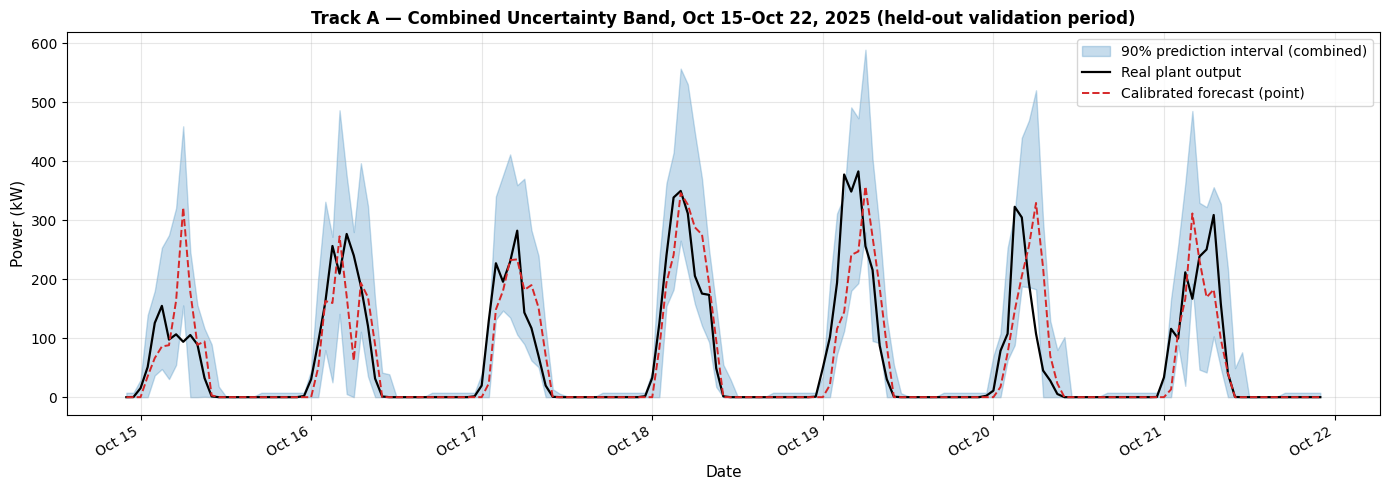

✅ Saved: /content/drive/MyDrive/Digital Twin and Data Driven(SMARD)/Digital Twin/Digital Twin site validation/model_outputs/figure_5_4_combined_uncertainty.png
  PICP on this slice (daylight): 85.7%
  Mean interval width: 94.4 kW


In [28]:
# ════════════════════════════════════════════════════════════════════════════
# FIGURE 5.4 — COMBINED UNCERTAINTY BAND VISUALISATION (for thesis)
# ════════════════════════════════════════════════════════════════════════════

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

# The validation arrays from Cell 9 cover Oct-Dec 2025 only
# real_vl: real plant kW on validation period
# pred_vl: calibrated LSTM prediction on validation period
# stat_lo, stat_hi: statistical-only intervals
# comb_lo, comb_hi: combined (statistical + physics) intervals
# ph_lo, ph_hi: physics-only intervals

# Get the timestamp index for the validation period
# This should be the timestamps corresponding to X_ev
val_index = X_ev.index if hasattr(X_ev, 'index') else None

if val_index is None:
    # Fallback: reconstruct index from real_vl if it's a pandas Series
    if hasattr(real_vl, 'index'):
        val_index = real_vl.index
    else:
        # Last resort: assume hourly Oct 1 - Dec 31
        val_index = pd.date_range("2025-10-01", "2025-12-31 23:00",
                                   freq="h", tz=TIMEZONE)[:len(real_vl)]

# Pick a representative week within Oct-Dec
SAMPLE_START = pd.Timestamp("2025-10-15", tz=TIMEZONE)
SAMPLE_END   = pd.Timestamp("2025-10-22", tz=TIMEZONE)

# Build a mask for the sample week
mask = (val_index >= SAMPLE_START) & (val_index <= SAMPLE_END)
time_slice = val_index[mask]

# Convert arrays to ensure indexing works
real_arr   = np.asarray(real_vl)
pred_arr   = np.asarray(pred_vl)
comb_lo_arr = np.asarray(comb_lo)
comb_hi_arr = np.asarray(comb_hi)

# Slice
real_slice    = real_arr[mask]
forecast_slice = pred_arr[mask]
q05_slice     = comb_lo_arr[mask]
q95_slice     = comb_hi_arr[mask]

print(f"  Sample period: {SAMPLE_START.date()} to {SAMPLE_END.date()}")
print(f"  Sample size: {mask.sum()} hours")

# Create figure
fig, ax = plt.subplots(figsize=(14, 5))

# Shaded prediction interval (90% interval)
ax.fill_between(time_slice, q05_slice, q95_slice,
                alpha=0.25, color="#1f77b4",
                label="90% prediction interval (combined)")

# Real plant output
ax.plot(time_slice, real_slice,
        color="black", linewidth=1.6, label="Real plant output")

# Point forecast
ax.plot(time_slice, forecast_slice,
        color="#d62728", linewidth=1.4, linestyle="--",
        label="Calibrated forecast (point)")

# Formatting
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Power (kW)", fontsize=11)
ax.set_title(
    f"Track A — Combined Uncertainty Band, {SAMPLE_START.strftime('%b %d')}–"
    f"{SAMPLE_END.strftime('%b %d, %Y')} (held-out validation period)",
    fontsize=12, weight="bold"
)
ax.legend(loc="upper right", fontsize=10)
ax.grid(alpha=0.3)
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
plt.xticks(rotation=30, ha="right")

plt.tight_layout()

# Save figure
SAVE_PATH = f"{MODEL_DIR}/figure_5_4_combined_uncertainty.png"
plt.savefig(SAVE_PATH, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Saved: {SAVE_PATH}")

# Quick verification
in_band  = (real_slice >= q05_slice) & (real_slice <= q95_slice)
daylight = real_slice > 5.0
if daylight.sum() > 0:
    picp_slice = in_band[daylight].mean() * 100
    print(f"  PICP on this slice (daylight): {picp_slice:.1f}%")
print(f"  Mean interval width: {(q95_slice - q05_slice).mean():.1f} kW")

In [29]:
import sys, tensorflow, xgboost, sklearn, pvlib, pandas, numpy, matplotlib, scipy,plotly
print(f"Python: {sys.version.split()[0]}")
print(f"TensorFlow: {tensorflow.__version__}")
print(f"XGBoost: {xgboost.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"pvlib: {pvlib.__version__}")
print(f"pandas: {pandas.__version__}")
print(f"NumPy: {numpy.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"SciPy: {scipy.__version__}")
print(f"ploty:{ plotly.__version__}")

Python: 3.12.13
TensorFlow: 2.20.0
XGBoost: 3.3.0
scikit-learn: 1.6.1
pvlib: 0.15.2
pandas: 2.2.2
NumPy: 2.0.2
Matplotlib: 3.10.0
SciPy: 1.16.3
ploty:5.24.1
